In [1]:
!pip install -q segment-anything

In [2]:
"""
Máscaras por célula para los parches de campo brillante (malaria_processed).
"""
import argparse
import json
import shutil
import sys
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage as ndi
from skimage import filters, morphology
from tqdm.auto import tqdm

# Configuración
# --- Kaggle ---
INPUT_DIR = Path('/kaggle/input')                    # aquí aparece tu Dataset (malaria_processed)
DATA_DIR = Path('/tmp/malaria_processed')            # solo si el dataset viene como .zip sin extraer
OUT_DIR = Path('/tmp/malaria_masks')                 # .npz de trabajo (no se guardan como salida)
DRIVE_OUT_DIR = Path('/kaggle/working')              # el zip final queda aquí = pestaña Output
SAM_CKPT = '/tmp/sam_vit_b_01ec64.pth'               # fuera de /kaggle/working para no inflar la salida
SAM_URL = 'https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth'
SEED = 42
BOX_PAD = 4  # px de margen alrededor de la caja para recortar la máscara (evita fugas de SAM)


# Datos
def prepare_data():
    """Busca manifest.csv en el Dataset de Kaggle (Kaggle suele extraer los .zip al subirlos).
    Si solo hay un .zip sin extraer, lo descomprime en DATA_DIR. Devuelve (manifest, raíz de imágenes)."""
    found = sorted(INPUT_DIR.rglob('manifest.csv'))
    if found:
        mpath = found[0]
    else:
        zips = sorted(INPUT_DIR.rglob('malaria_processed.zip'))
        assert zips, f'No encontré manifest.csv ni malaria_processed.zip en {INPUT_DIR}. ¿Agregaste el Dataset al notebook?'
        if not any(DATA_DIR.rglob('manifest.csv')):
            DATA_DIR.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zips[0]) as zf:
                zf.extractall(DATA_DIR)
        mpath = next(DATA_DIR.rglob('manifest.csv'))
    manifest = pd.read_csv(mpath)
    manifest['cell_boxes'] = manifest['cell_boxes'].apply(json.loads)
    return manifest, mpath.parent


def load_gray(root, rel):
    return np.array(Image.open(root / rel).convert('L'))


# Segmentación
def _clip_box(box, shape, pad=0):
    r0, c0, r1, c1 = [int(v) for v in box]
    h, w = shape
    return max(r0 - pad, 0), max(c0 - pad, 0), min(r1 + pad, h), min(c1 + pad, w)


def _largest_overlap_component(fg, box_in_crop):
    """De una máscara binaria, deja solo el componente que más se solapa con la caja y rellena huecos."""
    lab, n = ndi.label(fg)
    if n == 0:
        return np.zeros_like(fg)
    inner = np.zeros_like(fg)
    r0, c0, r1, c1 = box_in_crop
    inner[r0:r1, c0:c1] = True
    overlap = ndi.sum(inner, lab, index=np.arange(1, n + 1))
    comp = lab == (int(np.argmax(overlap)) + 1)
    return ndi.binary_fill_holes(comp)


def otsu_masks(gray, boxes, pad=BOX_PAD):
    """Otsu dentro de cada caja (células más oscuras que el fondo). Devuelve lista de máscaras bool (H,W)."""
    H, W = gray.shape
    out = []
    for box in boxes:
        R0, C0, R1, C1 = _clip_box(box, (H, W), pad)
        r0, c0, r1, c1 = _clip_box(box, (H, W), 0)
        m = np.zeros((H, W), bool)
        crop = gray[R0:R1, C0:C1]
        if crop.size < 16 or crop.std() < 1e-3:
            out.append(m)
            continue
        fg = crop < filters.threshold_otsu(crop)
        fg = ndi.binary_opening(fg, structure=morphology.disk(1))
        comp = _largest_overlap_component(fg, (r0 - R0, c0 - C0, r1 - R0, c1 - C0))
        m[R0:R1, C0:C1] = comp
        out.append(m)
    return out


def load_sam(device):
    import torch
    from segment_anything import sam_model_registry, SamPredictor
    if not Path(SAM_CKPT).exists():
        import urllib.request
        print('Descargando checkpoint SAM ViT-B...')
        urllib.request.urlretrieve(SAM_URL, SAM_CKPT)
    sam = sam_model_registry['vit_b'](checkpoint=SAM_CKPT).to(device).eval()
    return SamPredictor(sam)


def sam_masks(predictor, gray, boxes, pad=BOX_PAD):
    """SAM con cajas como prompt: un solo embedding por parche, todas las cajas en un batch."""
    import torch
    H, W = gray.shape
    if len(boxes) == 0:
        return []
    predictor.set_image(np.stack([gray] * 3, axis=-1))
    b = np.array([[c0, r0, c1, r1] for r0, c0, r1, c1 in boxes], dtype=np.float32)
    bt = predictor.transform.apply_boxes_torch(torch.as_tensor(b, device=predictor.device), predictor.original_size)
    with torch.no_grad():
        m, _, _ = predictor.predict_torch(point_coords=None, point_labels=None, boxes=bt, multimask_output=False)
    m = m[:, 0].cpu().numpy()
    out = []
    for box, mk in zip(boxes, m):
        R0, C0, R1, C1 = _clip_box(box, (H, W), pad)
        r0, c0, r1, c1 = _clip_box(box, (H, W), 0)
        clipped = np.zeros((H, W), bool)
        clipped[R0:R1, C0:C1] = mk[R0:R1, C0:C1]          # recorta fugas fuera de la caja con margen
        comp = _largest_overlap_component(clipped, (r0, c0, r1, c1))
        out.append(comp)
    return out


def to_instance_map(masks, shape):
    """Mapa de instancias: etiqueta k = k-ésima caja. Las células grandes se pintan primero, las pequeñas encima."""
    inst = np.zeros(shape, np.uint16)
    for i in np.argsort([-int(m.sum()) for m in masks]):
        inst[masks[i]] = i + 1
    return inst


def iou(a, b):
    u = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / u) if u else np.nan


# Subcomandos
def _sample_rows(manifest, n, split=None):
    df = manifest if split is None else manifest[manifest['split'] == split]
    return df.sample(n=min(n, len(df)), random_state=SEED)


def _sync():
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.synchronize()
    except ImportError:
        pass


def cmd_bench(args):
    import torch
    manifest, root = prepare_data()
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f'Dispositivo: {device}')
    rows = _sample_rows(manifest, args.n)
    predictor = load_sam(device)
    # calentamiento (la primera llamada incluye inicialización de CUDA)
    r0 = rows.iloc[0]
    sam_masks(predictor, load_gray(root, r0['file']), r0['cell_boxes'])

    for name, fn in [('SAM (SamPredictor + cajas)', lambda g, b: sam_masks(predictor, g, b)),
                     ('Otsu por caja', otsu_masks)]:
        _sync()
        t0 = time.perf_counter()
        for _, r in rows.iterrows():
            fn(load_gray(root, r['file']), r['cell_boxes'])
        _sync()
        dt = (time.perf_counter() - t0) / len(rows)
        total = len(manifest)
        print(f'{name:28s} {dt:6.3f} s/parche -> {total} parches ~ {dt * total / 60:6.1f} min')


def cmd_sanity(args):
    import matplotlib.pyplot as plt
    import torch
    manifest, root = prepare_data()
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    predictor = load_sam(device)
    rows = _sample_rows(manifest, args.n)
    sdir = OUT_DIR / 'sanity'
    sdir.mkdir(parents=True, exist_ok=True)

    per_cell, per_patch = [], []
    overlays = []
    for _, r in tqdm(rows.iterrows(), total=len(rows)):
        gray = load_gray(root, r['file'])
        boxes = r['cell_boxes']
        ms, mo = sam_masks(predictor, gray, boxes), otsu_masks(gray, boxes)
        for k, (a, b) in enumerate(zip(ms, mo)):
            per_cell.append({'file': r['file'], 'cell': k, 'iou': iou(a, b),
                             'area_sam': int(a.sum()), 'area_otsu': int(b.sum())})
        per_patch.append({'file': r['file'], 'n_cells': len(boxes),
                          'iou_union': iou(np.any(ms, axis=0) if ms else np.zeros_like(gray, bool),
                                           np.any(mo, axis=0) if mo else np.zeros_like(gray, bool))})
        if len(overlays) < 8:
            overlays.append((gray, ms, mo, r['file']))

    cells, patches = pd.DataFrame(per_cell), pd.DataFrame(per_patch)
    cells.to_csv(sdir / 'sanity_cells.csv', index=False)
    patches.to_csv(sdir / 'sanity_patches.csv', index=False)
    print(f'IoU por célula  SAM vs Otsu: media={cells.iou.mean():.3f} mediana={cells.iou.median():.3f} '
          f'p10={cells.iou.quantile(0.1):.3f}  (n={len(cells)})')
    print(f'IoU unión/parche: media={patches.iou_union.mean():.3f}')
    print(f'Fracción de células con IoU < 0.7: {(cells.iou < 0.7).mean():.1%}')

    fig, axes = plt.subplots(2, len(overlays), figsize=(3 * len(overlays), 6), squeeze=False)
    for j, (gray, ms, mo, name) in enumerate(overlays):
        for i, (masks, title) in enumerate([(ms, 'SAM'), (mo, 'Otsu')]):
            axes[i][j].imshow(gray, cmap='gray', vmin=0, vmax=255)
            if masks:
                axes[i][j].contour(np.any(masks, axis=0), levels=[0.5], colors='r', linewidths=0.8)
            axes[i][j].set_title(f'{title}\n{Path(name).stem[-14:]}', fontsize=7)
            axes[i][j].axis('off')
    plt.tight_layout()
    fig.savefig(sdir / 'sanity_overlays.png', dpi=130)
    print(f'Guardado en {sdir}')
    plt.show()


def cmd_run(args):
    import torch
    manifest, root = prepare_data()
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    predictor = load_sam(device) if args.method == 'sam' else None
    out_root = OUT_DIR / f'masks_{args.method}'

    todo = manifest[manifest['split'].isin(args.splits)]
    done = skipped = 0
    for _, r in tqdm(todo.iterrows(), total=len(todo)):
        out = out_root / r['split'] / (Path(r['file']).stem + '.npz')
        if out.exists():
            skipped += 1
            continue
        gray = load_gray(root, r['file'])
        boxes = r['cell_boxes']
        masks = sam_masks(predictor, gray, boxes) if args.method == 'sam' else otsu_masks(gray, boxes)
        out.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(out, inst=to_instance_map(masks, gray.shape),
                            boxes=np.array(boxes, dtype=np.int32).reshape(-1, 4))
        done += 1
    print(f'Listo: {done} nuevos, {skipped} ya existían.')

    zip_path = Path(shutil.make_archive(str(OUT_DIR / f'malaria_masks_{args.method}'), 'zip', root_dir=out_root))
    DRIVE_OUT_DIR.mkdir(parents=True, exist_ok=True)
    print('Zip final en Kaggle (pestaña Output):', shutil.copy2(zip_path, DRIVE_OUT_DIR / zip_path.name))


def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = p.add_subparsers(dest='cmd', required=True)
    b = sub.add_parser('bench'); b.add_argument('--n', type=int, default=50); b.set_defaults(fn=cmd_bench)
    s = sub.add_parser('sanity'); s.add_argument('--n', type=int, default=40); s.set_defaults(fn=cmd_sanity)
    r = sub.add_parser('run')
    r.add_argument('--method', choices=['sam', 'otsu'], required=True)
    r.add_argument('--splits', nargs='+', default=['Training', 'Validation'])
    r.set_defaults(fn=cmd_run)
    args = p.parse_args(argv)
    args.fn(args)


# Al pegar el script en una celda de Colab/Jupyter no se autoejecuta: llama main([...]) a mano.
if __name__ == '__main__' and 'ipykernel' not in sys.modules:
    main()

In [3]:
main(['bench', '--n', '50'])

Dispositivo: cuda
Descargando checkpoint SAM ViT-B...
SAM (SamPredictor + cajas)    0.543 s/parche -> 12616 parches ~  114.3 min
Otsu por caja                 0.011 s/parche -> 12616 parches ~    2.4 min


  0%|          | 0/40 [00:00<?, ?it/s]

IoU por célula  SAM vs Otsu: media=0.858 mediana=0.941 p10=0.662  (n=391)
IoU unión/parche: media=0.928
Fracción de células con IoU < 0.7: 13.0%
Guardado en /tmp/malaria_masks/sanity


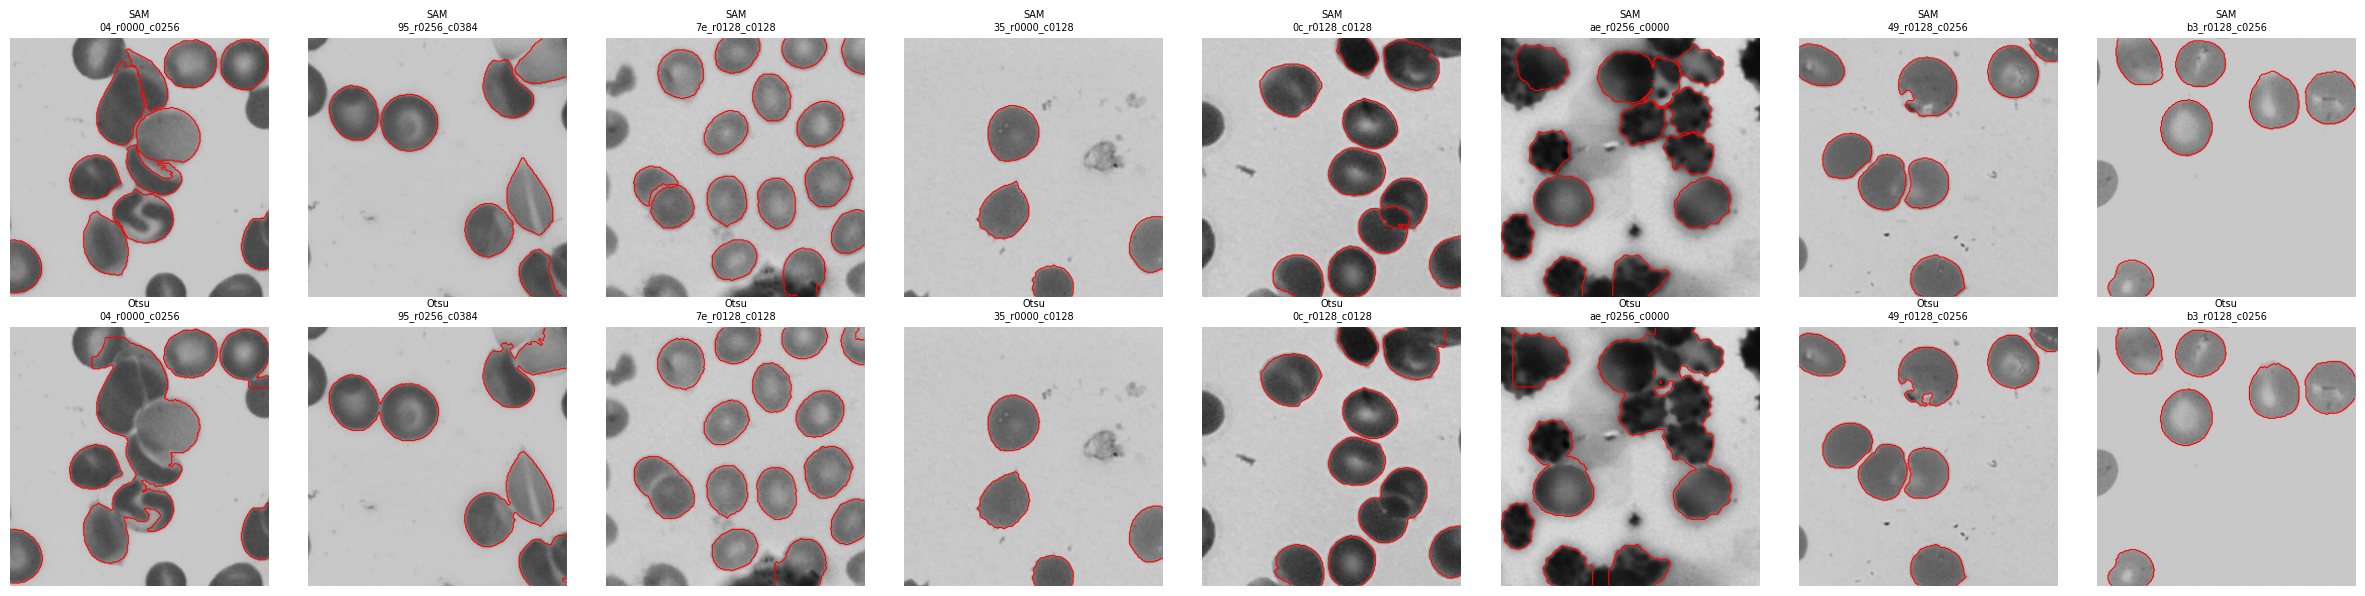

In [4]:
main(['sanity', '--n', '40'])

In [5]:
main(['run', '--method', 'sam', '--splits', 'Validation'])
main(['run', '--method', 'sam', '--splits', 'Training'])

  0%|          | 0/2517 [00:00<?, ?it/s]

Listo: 2517 nuevos, 0 ya existían.
Zip final en Kaggle (pestaña Output): /kaggle/working/malaria_masks_sam.zip


  0%|          | 0/10099 [00:00<?, ?it/s]

Listo: 10099 nuevos, 0 ya existían.
Zip final en Kaggle (pestaña Output): /kaggle/working/malaria_masks_sam.zip
